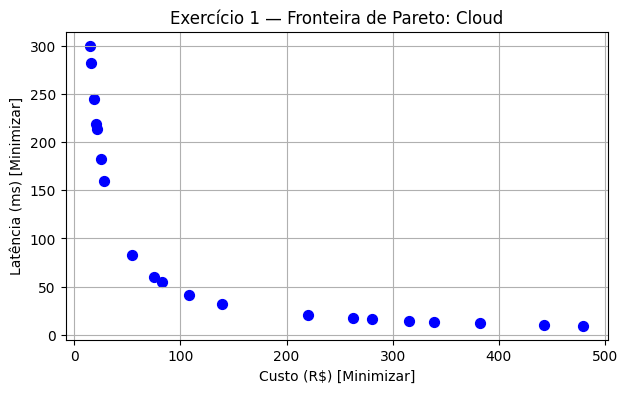

In [1]:
!pip install pymoo matplotlib -q

import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class CloudProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=1, n_obj=2, xl=np.array([1.0]), xu=np.array([32.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        vcpus = x[0]
        f1_custo = vcpus * 15.0         # R$ 15 por vCPU
        f2_latencia = 300.0 / vcpus     # Latência cai com mais vCPUs
        out["F"] = [f1_custo, f2_latencia]

res1 = minimize(CloudProblem(), NSGA2(pop_size=20), termination=('n_gen', 30), seed=1)

# Visualização
plt.figure(figsize=(7, 4))
plt.scatter(res1.F[:, 0], res1.F[:, 1], color='blue', s=50)
plt.title("Exercício 1 — Fronteira de Pareto: Cloud")
plt.xlabel("Custo (R$) [Minimizar]")
plt.ylabel("Latência (ms) [Minimizar]")
plt.grid(True)
plt.show()